<a href="https://colab.research.google.com/github/Joshua-A-tech/ALX_python/blob/main/K_means_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Simple K-Means Clustering Project

This notebook demonstrates a simple machine learning project using the **K-Means** clustering algorithm.

We will:
- Generate synthetic 2D cluster data using `scikit-learn`.
- Visualise the unlabelled data.
- Train a K-Means model to find the clusters.
- Plot the clustered data along with the calculated centroids.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

# Set style for plotting
sns.set_theme(style='whitegrid')
print("Libraries successfully imported!")

Libraries successfully imported!


## Step 1: Generate Synthetic Data
We will generate 2D data containing 4 distinct clusters.

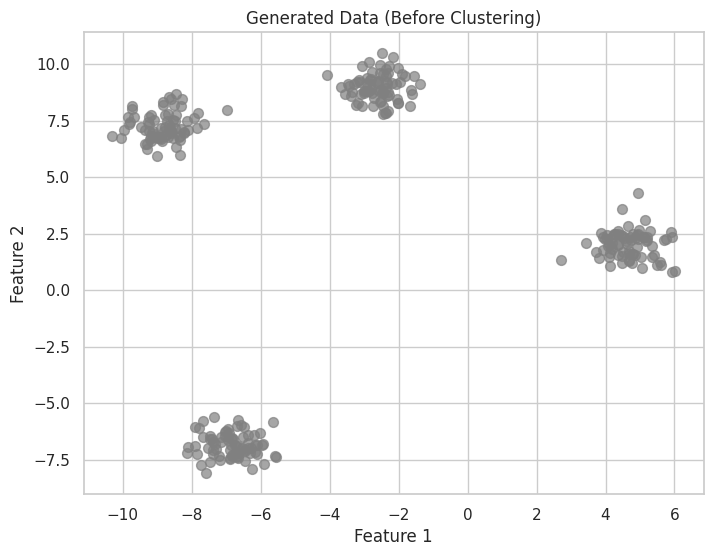

In [ ]:
# Generate synthetic 2D data
X, y_true = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=42)

# Visualize the raw, unlabelled data
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], s=50, color='gray', alpha=0.7)
plt.title("Generated Data (Before Clustering)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

## Step 2: Fit K-Means Model
Now we initialize and train the K-Means model using `n_clusters=4`.

In [ ]:
# Initialize K-Means
kmeans = KMeans(n_clusters=4, random_state=42, n_init='auto')

# Fit the model and predict cluster labels
y_kmeans = kmeans.fit_predict(X)

# Get the centroids of each cluster
centroids = kmeans.cluster_centers_
print("Model training complete. Centroids located at:\n", centroids)

Model training complete. Centroids located at:
 [[-2.60516878  8.99280115]
 [-6.85126211 -6.85031833]
 [ 4.68687447  2.01434593]
 [-8.83456141  7.24430734]]


## Step 3: Visualise the Clusters and Centroids
Finally, we plot the data colored by their predicted cluster and mark the calculated centroids.

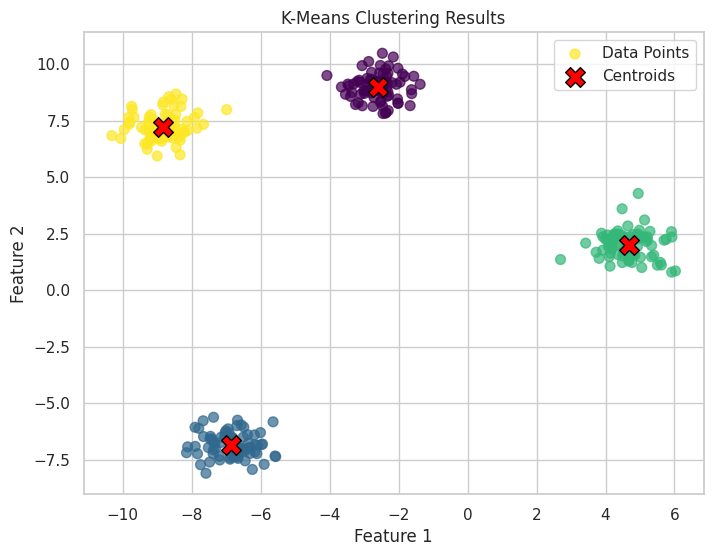

In [ ]:
plt.figure(figsize=(8, 6))

# Plot the clustered data points
plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=50, cmap='viridis', alpha=0.7, label='Data Points')

# Plot the centroids
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', s=200, marker='X', edgecolors='black', label='Centroids')

plt.title("K-Means Clustering Results")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

## Real-World Application: Customer Segmentation

In this project, we apply K-Means clustering to segment customers based on their purchasing behaviour using the **RFM model**:
- **Recency (R)**: Days since last purchase (lower is better).
- **Frequency (F)**: Total number of purchases (higher is better).
- **Monetary Value (M)**: Total money spent (higher is better).

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Generate realistic RFM customer data
np.random.seed(42)
n_customers = 500

# Creating 3 distinct artificial customer archetypes
# 1. High-value loyal customers (Low Recency, High Frequency, High Spend)
# 2. At-risk/churned customers (High Recency, Low Frequency, Low Spend)
# 3. New/Occasional customers (Medium Recency, Low Frequency, Medium Spend)

group_1 = np.random.multivariate_normal([10, 30, 1500], [[15, 5, 100], [5, 10, 50], [100, 50, 15000]], 150)
group_2 = np.random.multivariate_normal([120, 3, 150], [[400, 1, 10], [1, 2, 5], [10, 5, 1000]], 200)
group_3 = np.random.multivariate_normal([45, 8, 450], [[100, 2, 20], [2, 4, 15], [20, 15, 4000]], 150)

raw_data = np.vstack([group_1, group_2, group_3])
df_customer = pd.DataFrame(raw_data, columns=['Recency', 'Frequency', 'Monetary'])

# Clean negative values that can occasionally happen during normal distribution sampling
df_customer['Recency'] = df_customer['Recency'].clip(lower=1)
df_customer['Frequency'] = df_customer['Frequency'].clip(lower=1).astype(int)
df_customer['Monetary'] = df_customer['Monetary'].clip(lower=10)

display(df_customer.head())

,Recency,Frequency,Monetary
0,9.175451,31,1439.162155
1,9.906080,29,1313.460035
2,6.664961,26,1306.609516
3,11.837776,29,1433.535054
4,18.944193,30,1470.303480


### Feature Scaling
K-Means uses distance calculations, so we must standardise the variables first.

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_customer)

df_scaled = pd.DataFrame(X_scaled, columns=['Recency_Scaled', 'Frequency_Scaled', 'Monetary_Scaled'])
display(df_scaled.head())

,Recency_Scaled,Frequency_Scaled,Monetary_Scaled
0,-1.121019,1.564128,1.392450
1,-1.106281,1.397696,1.174176
2,-1.171662,1.148048,1.162280
3,-1.067314,1.397696,1.382679
4,-0.923961,1.480912,1.446526


### Finding the Optimal Number of Clusters (Elbow Method)

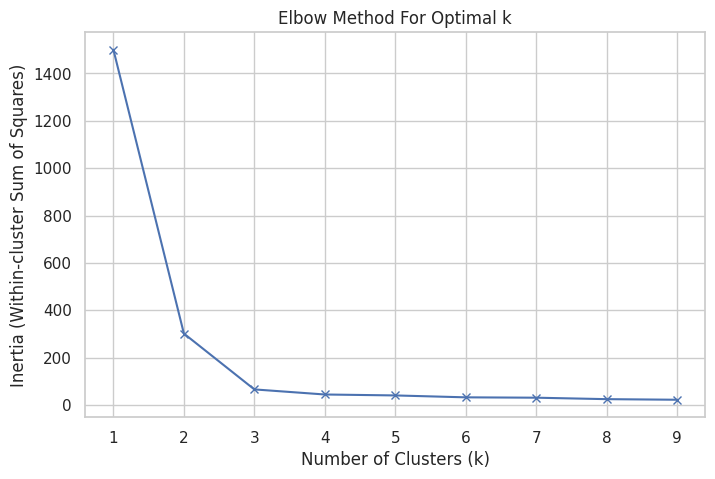

In [ ]:
inertia = []
K_range = range(1, 10)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init='auto')
    km.fit(X_scaled)
    inertia.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, 'bx-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Within-cluster Sum of Squares)')
plt.title('Elbow Method For Optimal k')
plt.show()

### Training the Final Customer Segmentation Model
We will fit the K-Means algorithm using `n_clusters=3` based on the elbow plot.

In [ ]:
kmeans_customer = KMeans(n_clusters=3, random_state=42, n_init='auto')
df_customer['Cluster'] = kmeans_customer.fit_predict(X_scaled)

# Calculate profile averages for each cluster
cluster_profiles = df_customer.groupby('Cluster').mean().reset_index()

# Assign descriptive business labels based on profiles
# Cluster mapping will depend on centroids' feature sizes
print(cluster_profiles)

   Cluster     Recency  Frequency     Monetary
0        0  121.096578   2.550505   148.145044
1        1   10.241549  29.966667  1491.130683
2        2   45.134471   7.250000   431.772727


### Visualise Customer Segments

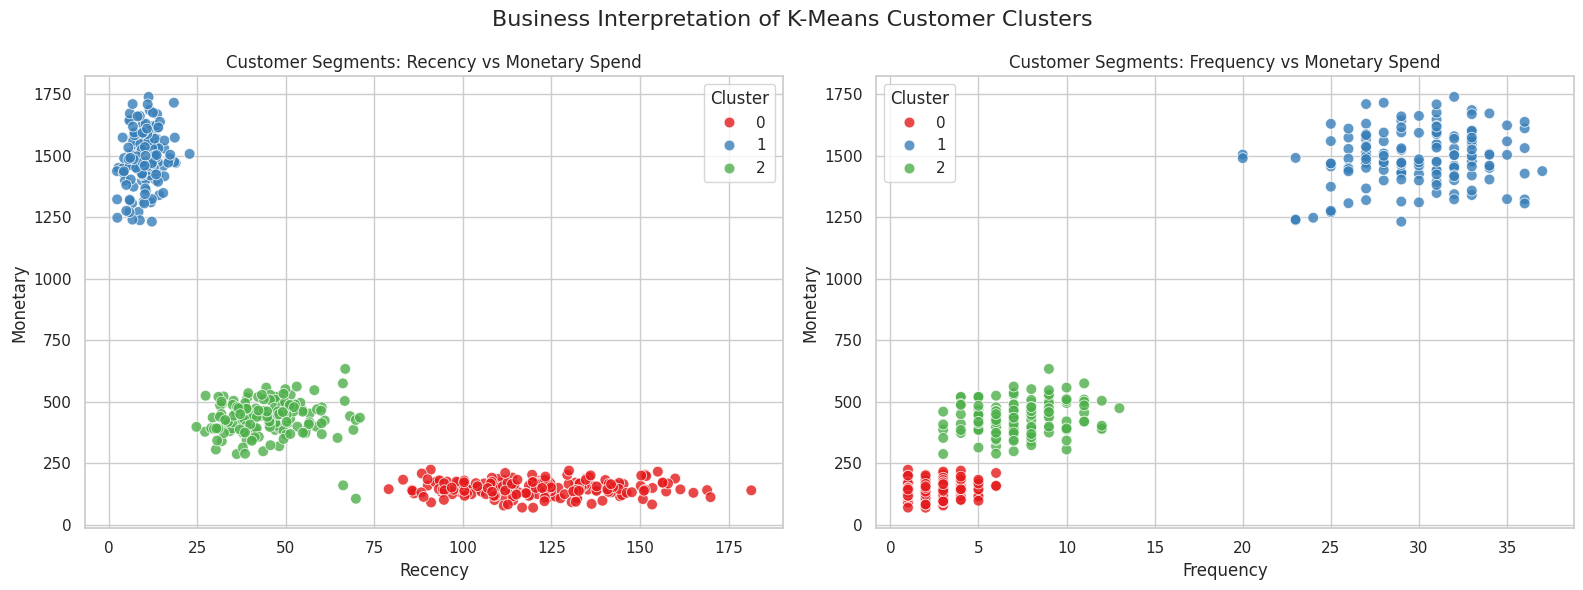

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot Recency vs Monetary
sns.scatterplot(
    data=df_customer, x='Recency', y='Monetary', hue='Cluster',
    palette='Set1', ax=axes[0], s=60, alpha=0.8
)
axes[0].set_title('Customer Segments: Recency vs Monetary Spend')

# Plot Frequency vs Monetary
sns.scatterplot(
    data=df_customer, x='Frequency', y='Monetary', hue='Cluster',
    palette='Set1', ax=axes[1], s=60, alpha=0.8
)
axes[1].set_title('Customer Segments: Frequency vs Monetary Spend')

plt.suptitle('Business Interpretation of K-Means Customer Clusters', fontsize=16)
plt.tight_layout()
plt.show()